In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import mudata

In [12]:
data_dir = "/scenic_plus_vol/SCENIC/full_dataset"

In [ ]:
# Read in gene expression data and aggregate by cell type
gex_data = sc.read_h5ad(f"{data_dir}/GEX.h5ad")
cell_metadata = gex_data.obs
cell_metadata.index = [f"{c}___cisTopic" for c in cell_metadata.index]
gex_data= sc.get.aggregate(
    gex_data, by=["L3_manual"], func=["mean"]
)
gex_data.X = gex_data.layers["mean"]

In [ ]:
# Read in scenicplus results per downsampled run and combine into one dataframe
reps = [ "downsampled_rep2", "100_000_cells_scplus_pipeline_out"]
gene_auc_dfs = {}
region_auc_dfs = {}
for rep in reps:
    scplus_aucell = mudata.read(f"{data_dir}/{rep}/AUCell_direct.h5mu")
    scplus_aucell.obs = scplus_aucell.obs.join(cell_metadata, how="left")

    # Group by cell type
    group_by = scplus_aucell.obs["L3_manual"].tolist()
    gene_auc_dfs[rep] = scplus_aucell["Gene_based"].to_df().groupby(group_by).mean()
    gene_auc_dfs[rep].columns = [c.split("_(")[0] for c in gene_auc_dfs[rep].columns]
    region_auc_dfs[rep] = scplus_aucell["Region_based"].to_df().groupby(group_by).mean()
    region_auc_dfs[rep].columns = [c.split("_(")[0] for c in region_auc_dfs[rep].columns]

    # check that the eRegulons are in the same order for gene and region-based AUCs
    assert np.all([c.split("_(")[0] for c in gene_auc_dfs[rep].columns] == [c.split("_(")[0] for c in region_auc_dfs[rep].columns])

# Subset to eRegulons detected in all reps
eregulons_detected_in_all_reps = list(set.intersection(*[set(gene_auc_dfs[r].columns.values) for r in reps]))
for rep in reps:
    gene_auc_dfs[rep] = gene_auc_dfs[rep][eregulons_detected_in_all_reps]
    region_auc_dfs[rep] = region_auc_dfs[rep][eregulons_detected_in_all_reps]

# Average AUCs across reps
gene_auc_df = sum([gene_auc_dfs[r] for r in reps])/len(reps)
region_auc_df = sum([region_auc_dfs[r] for r in reps])/len(reps)

/opt/conda/envs/single_cell/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/opt/conda/envs/single_cell/lib/python3.10/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)
/opt/conda/envs/single_cell/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() wi

In [103]:
# Subset gene expression data to TFs and re-order to match scenicplus results
tf_names = [x.split("_")[0] for x in gene_auc_df.columns.values]
tf_expression = gex_data[:,tf_names].to_df()
tf_expression.columns = gene_auc_df.columns.values

In [104]:
# filter to eRegulons with a gene or region-based AUC > 0.25 in at least one cell type
max_gene_based_AUC = gene_auc_df.max(axis=0)
max_region_based_AUC = region_auc_df.max(axis=0)

selected_eRegulons_gene_based_names = max_gene_based_AUC[(max_gene_based_AUC > 0.25).values | (max_region_based_AUC > 0.25).values].index.values
selected_eRegulons_region_based_names = max_region_based_AUC[(max_gene_based_AUC > 0.25).values | (max_region_based_AUC > 0.25).values].index.values

# rescale dataframes for plotting
def _scale(df):
    return (df - df.min())/(df.max() - df.min())

rescaled_gene_df = _scale(gene_auc_df[selected_eRegulons_gene_based_names])
rescaled_region_df = _scale(region_auc_df[selected_eRegulons_region_based_names])
rescaled_tf_expression_df = (tf_expression[selected_eRegulons_gene_based_names] - tf_expression[selected_eRegulons_gene_based_names].mean(axis=0))/tf_expression[selected_eRegulons_gene_based_names].std(axis=0)

/tmp/ipykernel_36551/901108751.py:51: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


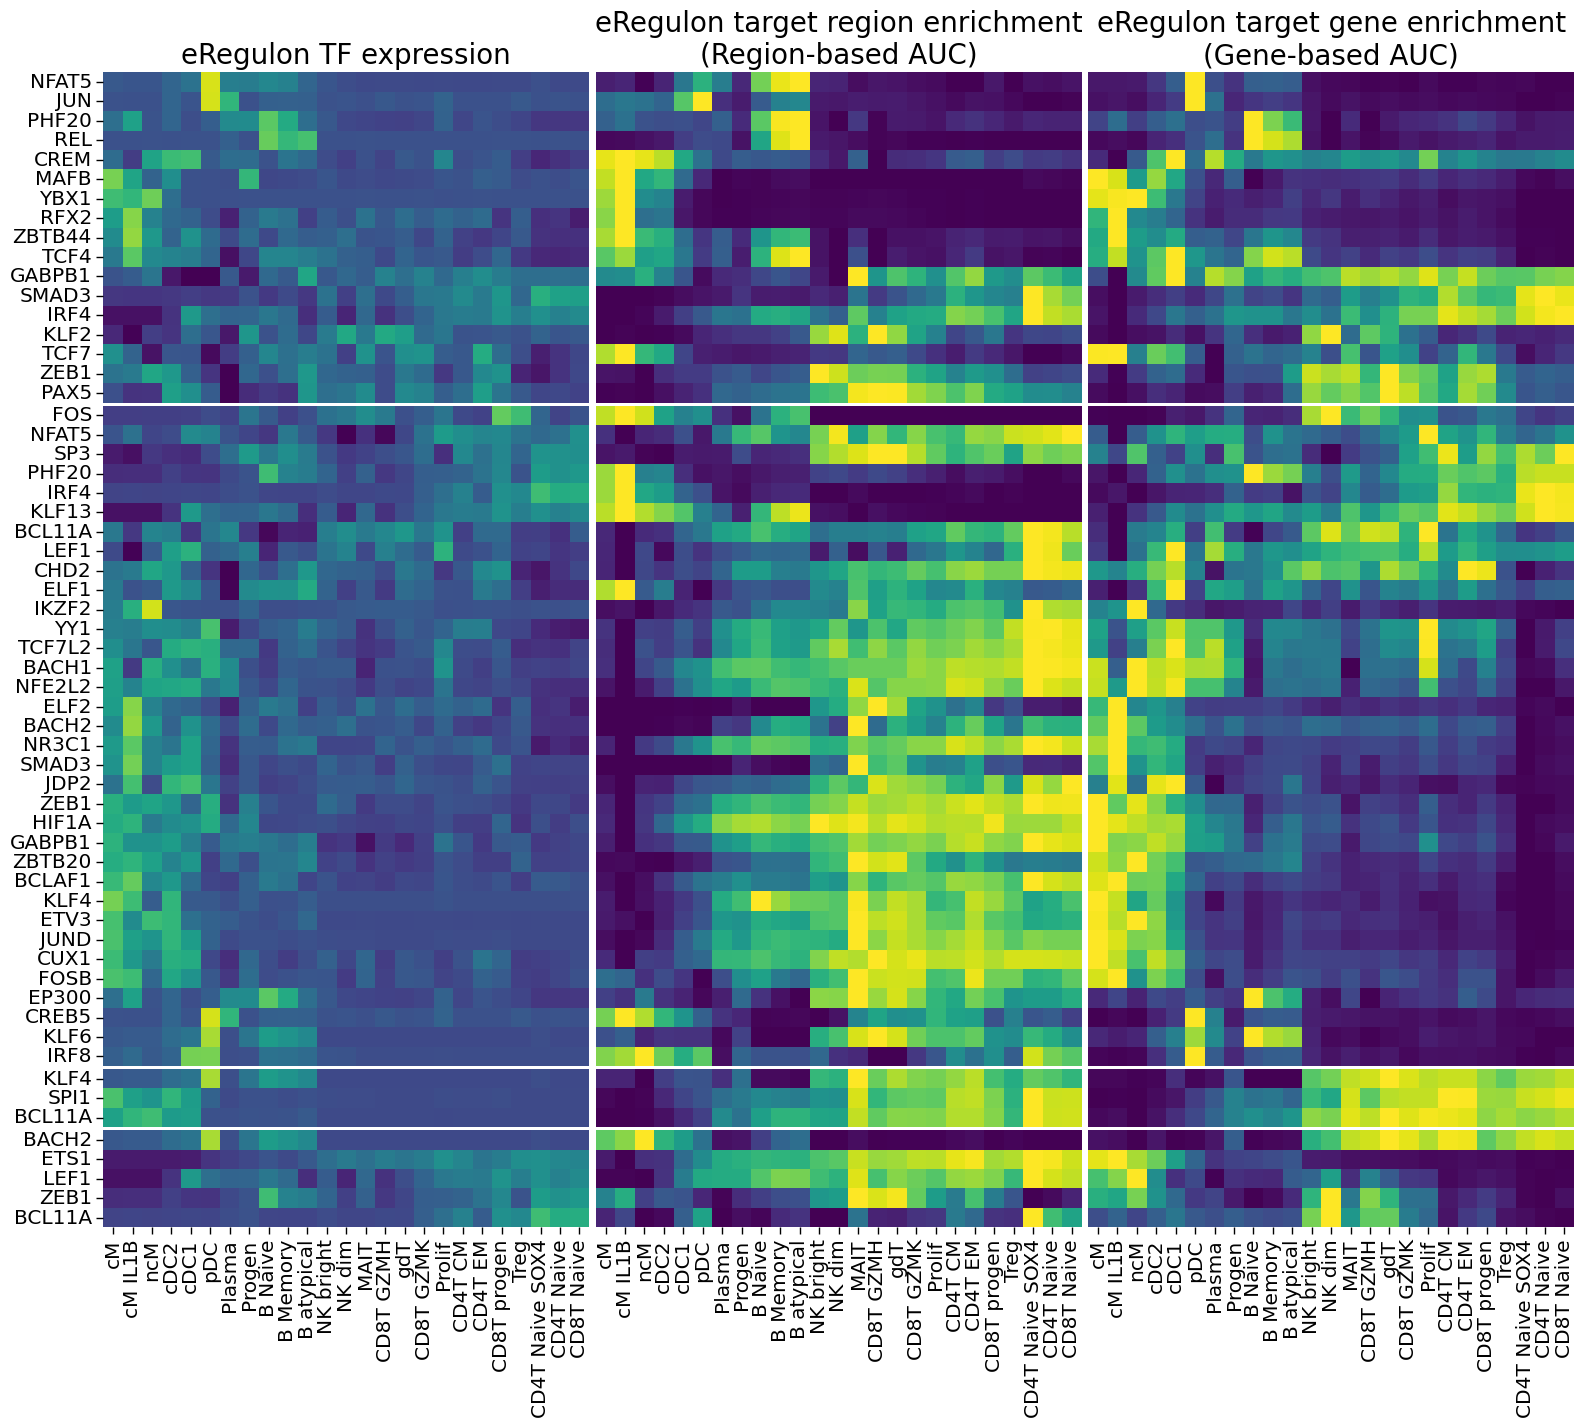

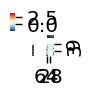

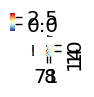

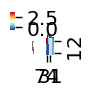

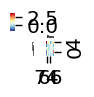

In [123]:
sns.set_context("paper", font_scale=1.65)

# cell type order
# cg_region = sns.clustermap(rescaled_region_df.T, cmap="RdYlBu_r", figsize=(1,1))
# col_order = cg_region.dendrogram_col.reordered_ind
col_order = [20, 21, 23, 19, 18, 24, 14, 15,  1,  0,  2, 12, 13, 11,  7, 22,  8, 16,  3,  4, 10, 17, 6,  5,  9]

# split eRegulons by activator/repressor
split_activator_repressor = np.array([c.split("_")[2] for c in rescaled_gene_df.columns])
activator_repressor_order, counts = np.unique(split_activator_repressor, return_counts=True)

# plot triplet heatmap
fig, ax = plt.subplots(4, 3, figsize=(19, 15), height_ratios=counts/counts.min())
plt.subplots_adjust(hspace=0.01, wspace=0.01)

for i, subset in enumerate(activator_repressor_order):
    # subset dataframes to activator/repressor
    rescaled_gene_df_subset = rescaled_gene_df.iloc[:,np.where(split_activator_repressor == subset)[0]]
    rescaled_region_df_subset = rescaled_region_df.iloc[:,np.where(split_activator_repressor == subset)[0]]
    rescaled_tf_expression_df_subset = rescaled_tf_expression_df.iloc[:,np.where(split_activator_repressor == subset)[0]]

    # get row order
    cg_all = sns.clustermap(np.vstack([rescaled_gene_df_subset, rescaled_region_df_subset, rescaled_tf_expression_df_subset]).T, 
                            cmap="RdYlBu_r", figsize=(1,1))
    row_order = cg_all.dendrogram_row.reordered_ind

    if i == 3:
        # xticklabels = True
        xticklabels = [c.replace("_", " ") for c in rescaled_gene_df_subset.index[col_order]]
    else:
        xticklabels = False
    yticklabels = [c.split("_")[0] for c in rescaled_gene_df_subset.columns.values]

    sns.heatmap(rescaled_tf_expression_df_subset.T.iloc[row_order, col_order],
                yticklabels=yticklabels, xticklabels=xticklabels, ax=ax[i,0], vmin=-2, vmax=4.5,
                cbar=False, square=True, cmap="viridis")

    sns.heatmap(rescaled_region_df_subset.T.iloc[row_order, col_order],
                yticklabels=False, xticklabels=xticklabels, ax=ax[i,1], vmin=0, vmax=1,
                cbar=False, square=True, cmap="viridis")

    sns.heatmap(rescaled_gene_df_subset.T.iloc[row_order, col_order],
                yticklabels=False, xticklabels=xticklabels, ax=ax[i, 2], vmin=0, vmax=1,
                cbar=False, square=True, cmap="viridis")

    if i == 0:
        ax[i,0].set_title("eRegulon TF expression", fontsize=20)
        ax[i,1].set_title("eRegulon target region enrichment\n(Region-based AUC)", fontsize=20)
        ax[i,2].set_title("eRegulon target gene enrichment\n(Gene-based AUC)", fontsize=20)

plt.tight_layout()
fig.savefig(f"{data_dir}/figures/eRegulon_triplet_heatmap_split_activator_repressor_vertical.pdf", dpi=300, bbox_inches="tight")
fig.savefig(f"{data_dir}/figures/eRegulon_triplet_heatmap_split_activator_repressor_vertical.png", dpi=300, bbox_inches="tight")

/opt/conda/envs/scenicplus/lib/python3.11/site-packages/seaborn/matrix.py:1113: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  self._figure.tight_layout(**tight_params)


(25, 24)


/opt/conda/envs/scenicplus/lib/python3.11/site-packages/seaborn/matrix.py:1113: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  self._figure.tight_layout(**tight_params)


(25, 4)
(25, 39)
(25, 5)


/tmp/ipykernel_28747/265128217.py:42: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


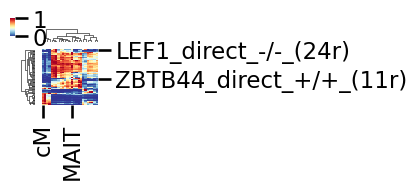

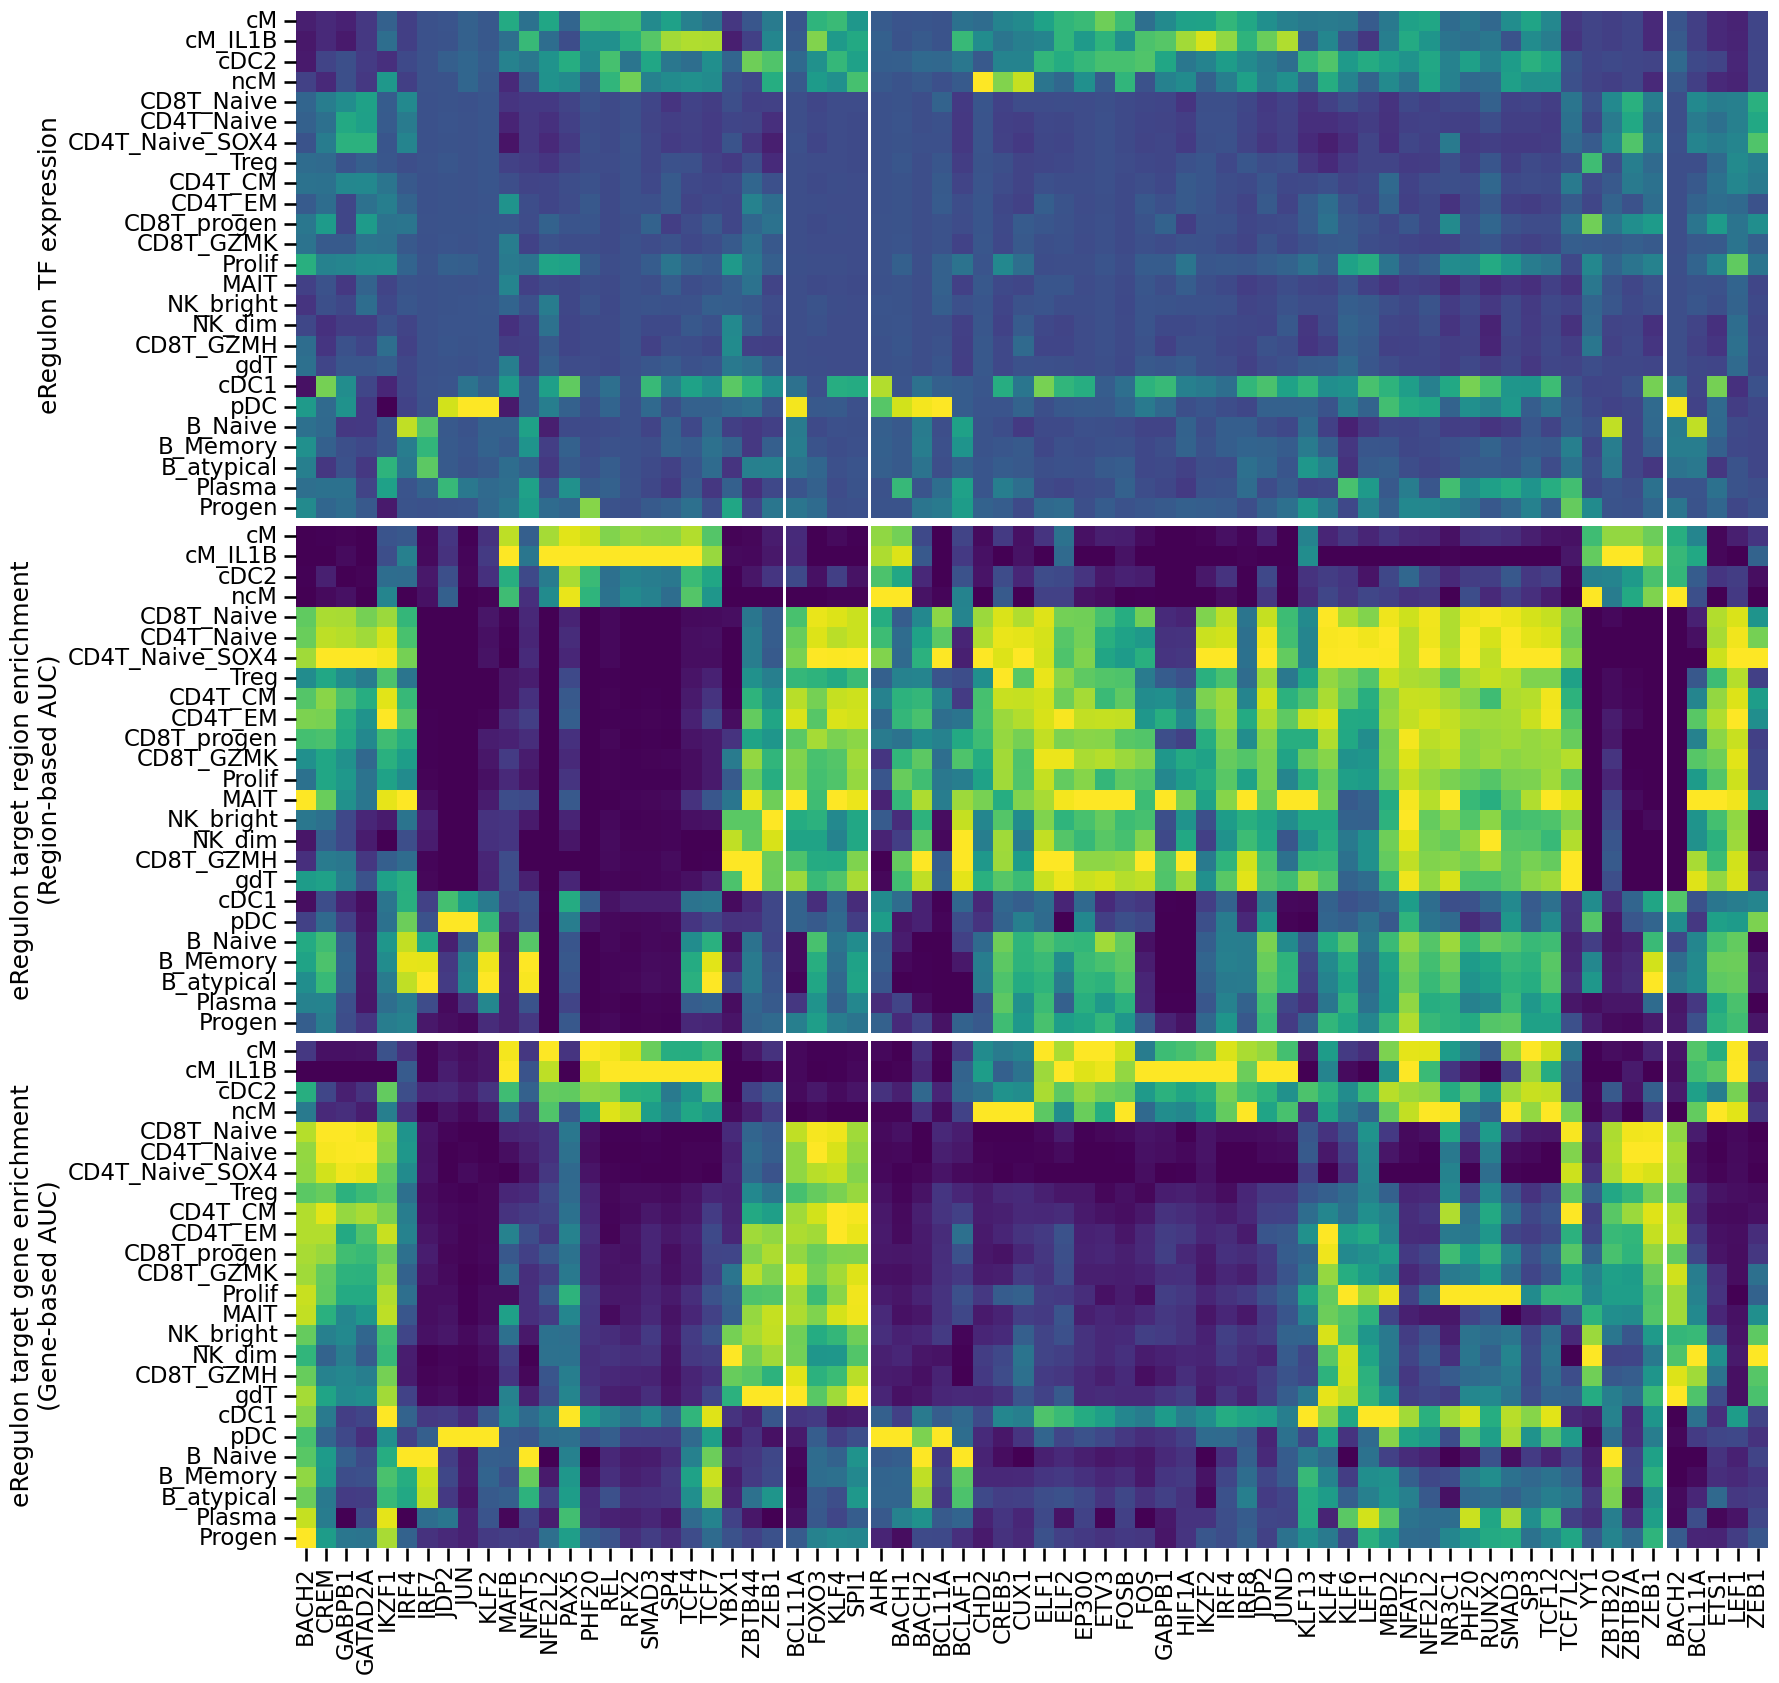

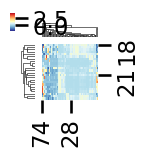

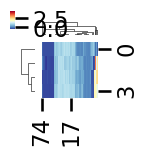

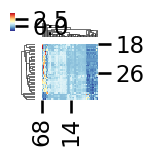

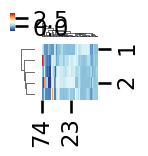

In [ ]:
sns.set_context("paper", font_scale=2)

# cell type order
# cg_region = sns.clustermap(rescaled_region_df.T, cmap="RdYlBu_r", figsize=(1,1))
# col_order = cg_region.dendrogram_col.reordered_ind
col_order = [20, 21, 23, 19, 18, 24, 14, 15,  1,  0,  2, 12, 13, 11,  7, 22,  8, 16,  3,  4, 10, 17, 6,  5,  9]

# split eRegulons by activator/repressor
split_activator_repressor = np.array([c.split("_")[2] for c in rescaled_gene_df.columns])
activator_repressor_order, counts = np.unique(split_activator_repressor, return_counts=True)

# plot triplet heatmap
fig, ax = plt.subplots(3, 4, figsize=(19, 20), width_ratios=counts/counts.min())
plt.subplots_adjust(hspace=0.01, wspace=0.01)

for i, subset in enumerate(activator_repressor_order):
    # subset dataframes to activator/repressor
    rescaled_gene_df_subset = rescaled_gene_df.iloc[:,np.where(split_activator_repressor == subset)[0]]
    rescaled_region_df_subset = rescaled_region_df.iloc[:,np.where(split_activator_repressor == subset)[0]]
    rescaled_tf_expression_df_subset = rescaled_tf_expression_df.iloc[:,np.where(split_activator_repressor == subset)[0]]

    # get row order
    cg_all = sns.clustermap(np.vstack([rescaled_gene_df_subset, rescaled_region_df_subset, rescaled_tf_expression_df_subset]).T, 
                            cmap="RdYlBu_r", figsize=(1,1))
    row_order = cg_all.dendrogram_row.reordered_ind

    if i == 0:
        yticklabels = True
    else:
        yticklabels = False
    xticklabels = [c.split("_")[0] for c in rescaled_gene_df_subset.columns.values]

    sns.heatmap(rescaled_tf_expression_df_subset.T.iloc[row_order, col_order].T,
                yticklabels=yticklabels, xticklabels=False, ax=ax[0,i], vmin=-2, vmax=4.5,
                cbar=False, square=True, cmap="viridis")

    sns.heatmap(rescaled_region_df_subset.T.iloc[row_order, col_order].T,
                yticklabels=yticklabels, xticklabels=False, ax=ax[1,i], vmin=0, vmax=1,
                cbar=False, square=True, cmap="viridis")

    sns.heatmap(rescaled_gene_df_subset.T.iloc[row_order, col_order].T,
                yticklabels=yticklabels, xticklabels=xticklabels, ax=ax[2,i], vmin=0, vmax=1,
                cbar=False, square=True, cmap="viridis")

    if i == 0:
        ax[0,i].set_ylabel("eRegulon TF expression")
        ax[1,i].set_ylabel("eRegulon target region enrichment\n(Region-based AUC)")
        ax[2,i].set_ylabel("eRegulon target gene enrichment\n(Gene-based AUC)")

plt.tight_layout()
fig.savefig(f"{data_dir}/figures/eRegulon_triplet_heatmap_split_activator_repressor_horizontal.pdf", dpi=300, bbox_inches="tight")
fig.savefig(f"{data_dir}/figures/eRegulon_triplet_heatmap_split_activator_repressor_horizontal.png", dpi=300, bbox_inches="tight")

### OLD

In [ ]:
# default scenic dotplot viz
heatmap_dotplot(
    scplus_mudata = scplus_mdata,
    color_modality = "direct_gene_based_AUC",
    size_modality = "direct_region_based_AUC",
    group_variable = "scRNA_counts:L3_manual",
    eRegulon_metadata_key = "direct_e_regulon_metadata",
    color_feature_key = "Gene_signature_name",
    size_feature_key = "Region_signature_name",
    feature_name_key = "eRegulon_name",
    sort_data_by = "direct_gene_based_AUC",
    subset_feature_names = selected_eRegulons_gene_based_names,
    orientation = "vertical",
    figsize = (8, 16),
)

Plot sharing of target genes or target regions across eRegulons

In [ ]:
gene_based_jaccard_df, _ = jaccard_heatmap(scplus_obj,
                gene_or_region_based = "Gene_based",
                selected_regulons = selected_eRegulons_gene_based_names, 
                use_plotly=False, figsize=(22, 20),
                fontsize=9, vmax=0.4, return_data=True)
plt.tight_layout()

gene_based_jaccard_df.index = [i.split("_(")[0] for i in gene_based_jaccard_df.index]
gene_based_jaccard_df.columns = [i.split("_(")[0] for i in gene_based_jaccard_df.columns]
gene_based_order = gene_based_jaccard_df.index.values

In [ ]:
region_based_jaccard_df, _ = jaccard_heatmap(scplus_obj,
                gene_or_region_based = "Region_based",
                selected_regulons = selected_eRegulons_region_based_names, 
                use_plotly=False, figsize=(22, 20),
                fontsize=9, vmax=0.3, return_data=True)
plt.tight_layout()


region_based_jaccard_df.index = [i.split("_(")[0] for i in region_based_jaccard_df.index]
region_based_jaccard_df.columns = [i.split("_(")[0] for i in region_based_jaccard_df.columns]
region_based_order = region_based_jaccard_df.index.values

In [ ]:
# plot both target gene and target region sharing in one heatmap, ordered based on gene-based clustering
gene_based_jaccard_df = gene_based_jaccard_df.loc[gene_based_order, gene_based_order]
region_based_jaccard_df = region_based_jaccard_df.loc[gene_based_order, gene_based_order]
combined_mat = gene_based_jaccard_df.values
combined_mat[np.tril_indices(combined_mat.shape[0])] = region_based_jaccard_df.values[np.tril_indices(combined_mat.shape[0])]

# Create masks
mask_lower = np.triu(np.ones_like(combined_mat, dtype=bool)) # Mask for upper triangle (hides upper)
mask_upper = np.tril(np.ones_like(combined_mat, dtype=bool)) # Mask for lower triangle (hides lower)

# Create a figure and axes
fig, ax = plt.subplots(figsize=(22, 20))

# Plot the lower triangle with one palette
sns.heatmap(combined_mat, mask=mask_lower, square=True,
            cbar_kws={"shrink": .50, 'label': 'Region-based Jaccard'},
            xticklabels=gene_based_jaccard_df.index.values,
            yticklabels=gene_based_jaccard_df.index.values,
            cmap='Blues', ax=ax, cbar=True,
            vmin=0, vmax=0.3) # Adjust vmin/vmax as needed

# Plot the upper triangle with a different palette
sns.heatmap(combined_mat, mask=mask_upper, square=True,
            cbar_kws={"shrink": .50, 'label': 'Target gene-based Jaccard'},
            xticklabels=gene_based_jaccard_df.index.values,
            yticklabels=gene_based_jaccard_df.index.values,
            cmap='Reds', ax=ax,
            vmin=0, vmax=0.3) # Adjust vmin/vmax as needed

plt.savefig(f"{data_dir}/figures/scenic_100_000_cells_jaccard_heatmap.png", dpi=300, bbox_inches='tight')

In [ ]:
# plot both target gene and target region sharing in one heatmap, ordered based on region-based clustering
gene_based_jaccard_df = gene_based_jaccard_df.loc[region_based_order, region_based_order]
region_based_jaccard_df = region_based_jaccard_df.loc[region_based_order, region_based_order]
combined_mat = gene_based_jaccard_df.values
combined_mat[np.tril_indices(combined_mat.shape[0])] = region_based_jaccard_df.values[np.tril_indices(combined_mat.shape[0])]

# Create masks
mask_lower = np.triu(np.ones_like(combined_mat, dtype=bool)) # Mask for upper triangle (hides upper)
mask_upper = np.tril(np.ones_like(combined_mat, dtype=bool)) # Mask for lower triangle (hides lower)

# Create a figure and axes
fig, ax = plt.subplots(figsize=(22, 20))

# Plot the lower triangle with one palette
sns.heatmap(combined_mat, mask=mask_lower, square=True,
            cbar_kws={"shrink": .50, 'label': 'Region-based Jaccard'},
            xticklabels=gene_based_jaccard_df.index.values,
            yticklabels=gene_based_jaccard_df.index.values,
            cmap='Blues', ax=ax, cbar=True,
            vmin=0, vmax=0.3) # Adjust vmin/vmax as needed

# Plot the upper triangle with a different palette
sns.heatmap(combined_mat, mask=mask_upper, square=True,
            cbar_kws={"shrink": .50, 'label': 'Target gene-based Jaccard'},
            xticklabels=gene_based_jaccard_df.index.values,
            yticklabels=gene_based_jaccard_df.index.values,
            cmap='Reds', ax=ax,
            vmin=0, vmax=0.3) # Adjust vmin/vmax as needed

plt.show()